# Лабораторна робота 2B. Багатошаровий персептрон

**Горбач Ангеліна, ФІ-31.**

Задача: за характеристиками вживаного автомобіля визначити одну з трьох цінових категорій. Використано публічний набір [Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho), файл `Car details v3.csv`.

Власний MLP реалізовано через NumPy. `scikit-learn` використано для підготовки ознак, метрик і порівняння з готовим `MLPClassifier`


## 1. Дані та первинний аналіз

Цільова змінна початкового набору — `selling_price`. Перед класифікацією перетворюю ціну на три категорії. Вхідні ознаки: рік випуску, пробіг, марка, паливо, тип продавця, коробка передач, кількість попередніх власників і технічні характеристики. Повну назву авто замінюю на марку, щоб не створювати сотні рідкісних категорій.


Початковий розмір: (8128, 13)
Повні дублікати: 1202
Пропуски до обробки:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
Аномальний пробіг: 2
Після очищення: 6924 оголошень


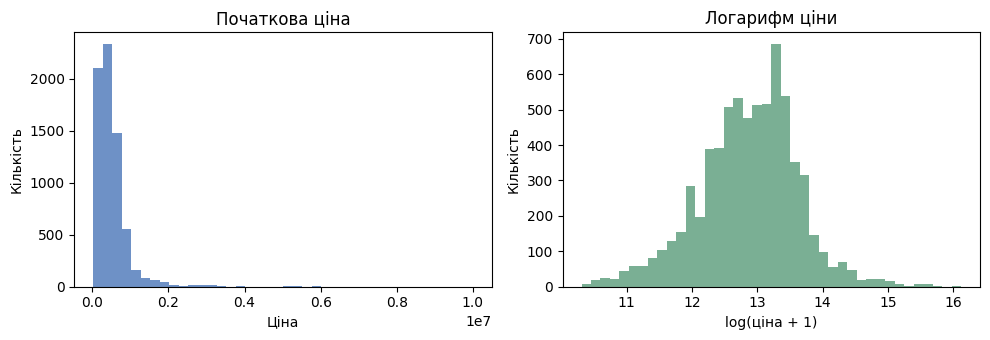

In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data = pd.read_csv(Path("Car details v3.csv"))
print("Початковий розмір:", data.shape)
print("Повні дублікати:", data.duplicated().sum())
print("Пропуски до обробки:")
print(data.isna().sum().to_string())

# Keep the first copy of each listing and remove implausible mileage.
data = data.drop_duplicates().copy()
outliers = (data["km_driven"] > 1_000_000).sum()
data = data.loc[data["km_driven"] <= 1_000_000].copy()
print("Аномальний пробіг:", outliers)
print("Після очищення:", len(data), "оголошень")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(data["selling_price"], bins=40, color="#6E91C6")
ax[0].set(title="Початкова ціна", xlabel="Ціна", ylabel="Кількість")
ax[1].hist(np.log1p(data["selling_price"]), bins=40, color="#7AAF94")
ax[1].set(title="Логарифм ціни", xlabel="log(ціна + 1)", ylabel="Кількість")
plt.tight_layout()
plt.show()


Ціни мають довгий правий хвіст: дорогі авто трапляються значно рідше. Для класифікації надалі використовую категорії ціни. Пропущені технічні характеристики заповнюються медіанами, обчисленими лише на навчальних даних.


## 2. Класи й поділ даних

Дані ділю у співвідношенні 70:30. Межі між дешевими, середніми й дорогими автомобілями — квантилі 1/3 і 2/3 **навчальної** вибірки. Тестова частина не впливає на ці межі. Саму ціну до вхідних ознак не додаю.


Межі цінових категорій: [300000, 550000]
Навчання: 4846 Тест: 2078
Класи на навчанні: {'низька': 1569, 'середня': 1574, 'висока': 1703}
Класи на тесті: {'низька': 679, 'середня': 689, 'висока': 710}


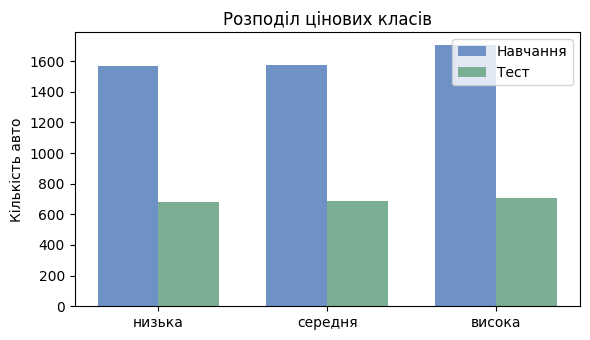

Медіани року й пробігу за класами (навчальні дані):
           year  km_driven
class                     
низька   2010.0    80000.0
середня  2014.0    70000.0
висока   2017.0    50000.0


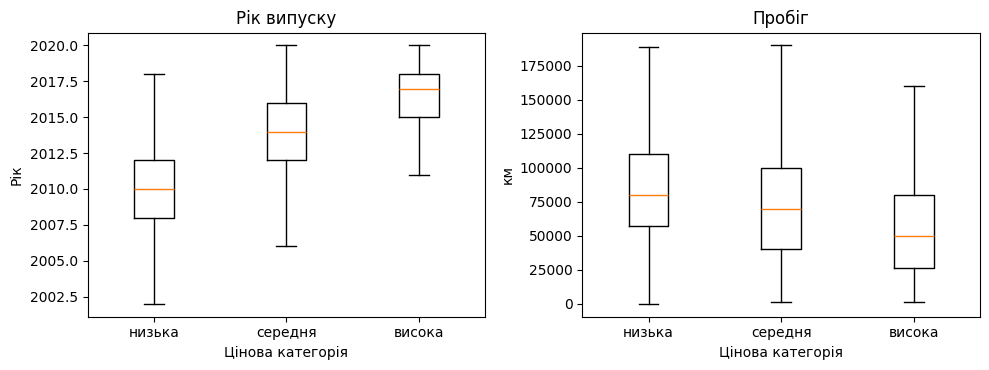

In [2]:
train_rows, test_rows = train_test_split(data, test_size=0.30, random_state=42)
price_limits = train_rows["selling_price"].quantile([1 / 3, 2 / 3]).to_numpy()
class_names = ["низька", "середня", "висока"]


def make_classes(prices):
    # Apply the same training-set boundaries to any set of cars.
    return np.searchsorted(price_limits, np.asarray(prices), side="right")


y_train = make_classes(train_rows["selling_price"])
y_test = make_classes(test_rows["selling_price"])
print("Межі цінових категорій:", price_limits.astype(int).tolist())
print("Навчання:", len(train_rows), "Тест:", len(test_rows))
print("Класи на навчанні:", {name: int(count) for name, count in zip(class_names, np.bincount(y_train))})
print("Класи на тесті:", {name: int(count) for name, count in zip(class_names, np.bincount(y_test))})

fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(3)
ax.bar(x - 0.18, np.bincount(y_train), width=0.36, label="Навчання", color="#6E91C6")
ax.bar(x + 0.18, np.bincount(y_test), width=0.36, label="Тест", color="#7AAF94")
ax.set_xticks(x, class_names)
ax.set(ylabel="Кількість авто", title="Розподіл цінових класів")
ax.legend()
plt.tight_layout()
plt.show()

# Compare two input features with the output classes, using training rows only.
relations = pd.DataFrame({"class": y_train, "year": train_rows["year"].to_numpy(),
                          "km_driven": train_rows["km_driven"].to_numpy()})
print("Медіани року й пробігу за класами (навчальні дані):")
print(relations.groupby("class")[["year", "km_driven"]].median().rename(index=dict(enumerate(class_names))).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (column, title, ylabel) in zip(axes, [("year", "Рік випуску", "Рік"),
                                              ("km_driven", "Пробіг", "км")]):
    samples = [relations.loc[relations["class"] == k, column] for k in range(3)]
    ax.boxplot(samples, tick_labels=class_names, showfliers=False)
    ax.set(title=title, xlabel="Цінова категорія", ylabel=ylabel)
plt.tight_layout()
plt.show()


На навчальних даних видно зв’язок між ознаками й класом: автомобілі високої цінової категорії зазвичай новіші й мають менший пробіг. Це не строгі правила для кожного авто, але такі ознаки допомагають класифікації.


## 3. Підготовка ознак

Із текстових значень витягую числа: витрату пального, об’єм двигуна, потужність і крутний момент. Для крутного моменту `kgm` переводжу у `Nm`. Пропуски заповнюю, числові ознаки масштабую, категорії перетворюю на окремі стовпці. Під час добору архітектури підготовка навчається тільки на внутрішній навчальній частині.


In [3]:
def first_number(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"\d+(?:\.\d+)?", str(value))
    return float(match.group()) if match else np.nan


def torque_in_nm(value):
    number = first_number(value)
    if pd.isna(number):
        return np.nan
    return number * 9.80665 if "kgm" in str(value).lower() else number


def get_features(rows):
    # The target price is deliberately absent from this table.
    features = rows[["year", "km_driven", "fuel", "seller_type", "transmission", "owner", "seats"]].copy()
    features["brand"] = rows["name"].str.split().str[0]
    features["mileage_value"] = rows["mileage"].map(first_number)
    features["engine_cc"] = rows["engine"].map(first_number)
    features["max_power_bhp"] = rows["max_power"].map(first_number)
    features["torque_nm"] = rows["torque"].map(torque_in_nm)
    features.loc[features["mileage_value"] <= 0, "mileage_value"] = np.nan
    features.loc[features["max_power_bhp"] <= 0, "max_power_bhp"] = np.nan
    return features


numeric_columns = ["year", "km_driven", "seats", "mileage_value", "engine_cc", "max_power_bhp", "torque_nm"]
category_columns = ["brand", "fuel", "seller_type", "transmission", "owner"]


def make_preprocessor():
    numbers = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categories = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                           ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numbers, numeric_columns),
                              ("cat", categories, category_columns)])


X_train_raw = get_features(train_rows)
X_test_raw = get_features(test_rows)
print("Вхідні стовпці:", X_train_raw.columns.tolist())
print("Пропуски серед підготовлених навчальних ознак:")
print(X_train_raw.isna().sum().to_string())


Вхідні стовпці: ['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'seats', 'brand', 'mileage_value', 'engine_cc', 'max_power_bhp', 'torque_nm']
Пропуски серед підготовлених навчальних ознак:
year               0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
seats            150
brand              0
mileage_value    158
engine_cc        150
max_power_bhp    151
torque_nm        151


## 4. Власна реалізація MLP

Перевіряю дві архітектури: один прихований шар із 24 нейронами та два приховані шари із 24 і 12 нейронами. На прихованих шарах використовую ReLU, на виході — softmax для трьох класів. Помилку обчислюю через кросентропію; ваги оновлюю зворотним поширенням помилки й Adam. Вибір роблю за внутрішньою перевірочною частиною, не за тестом.


In [8]:
class OwnMLP:
    def __init__(self, hidden_layers=(24,), learning_rate=0.003, l2=0.0001,
                 batch_size=128, seed=42):
        self.hidden_layers = hidden_layers
        self.learning_rate = learning_rate
        self.l2 = l2
        self.batch_size = batch_size
        self.seed = seed

    def _initialize(self, input_size, output_size):
        self.rng = np.random.default_rng(self.seed)
        sizes = (input_size, *self.hidden_layers, output_size)
        self.weights = [self.rng.normal(0, np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1]))
                        for i in range(len(sizes) - 1)]
        self.biases = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]
        self.mw = [np.zeros_like(w) for w in self.weights]
        self.vw = [np.zeros_like(w) for w in self.weights]
        self.mb = [np.zeros_like(b) for b in self.biases]
        self.vb = [np.zeros_like(b) for b in self.biases]
        self.step = 0

    def _forward(self, X):
        activations = [X]
        for w, b in zip(self.weights[:-1], self.biases[:-1]):
            activations.append(np.maximum(0, np.dot(activations[-1], w) + b))
        logits = np.dot(activations[-1], self.weights[-1]) + self.biases[-1]
        shifted = logits - logits.max(axis=1, keepdims=True)
        probabilities = np.exp(shifted)
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        return activations, probabilities

    def _loss(self, X, y):
        probabilities = self._forward(X)[1]
        return -np.log(np.maximum(probabilities[np.arange(len(y)), y], 1e-12)).mean()

    def _update(self, X, y):
        activations, probabilities = self._forward(X)
        delta = probabilities.copy()
        delta[np.arange(len(y)), y] -= 1
        delta /= len(y)
        dw = [None] * len(self.weights)
        db = [None] * len(self.biases)
        for layer in range(len(self.weights) - 1, -1, -1):
            dw[layer] = np.dot(activations[layer].T, delta) + self.l2 * self.weights[layer]
            db[layer] = delta.sum(axis=0)
            if layer:
                delta = np.dot(delta, self.weights[layer].T) * (activations[layer] > 0)
        self.step += 1
        for layer in range(len(self.weights)):
            # Adam adjusts each gradient using its moving averages.
            for parameter, gradient, mean, square in (
                (self.weights[layer], dw[layer], self.mw[layer], self.vw[layer]),
                (self.biases[layer], db[layer], self.mb[layer], self.vb[layer]),
            ):
                mean[:] = 0.9 * mean + 0.1 * gradient
                square[:] = 0.999 * square + 0.001 * gradient * gradient
                corrected_mean = mean / (1 - 0.9 ** self.step)
                corrected_square = square / (1 - 0.999 ** self.step)
                parameter -= self.learning_rate * corrected_mean / (np.sqrt(corrected_square) + 1e-8)

    def fit(self, X, y, epochs=160, validation=None, patience=18):
        self._initialize(X.shape[1], int(np.max(y)) + 1)
        self.history = {"train": [], "validation": []}
        best_loss = np.inf
        best_state = None
        self.best_epoch = epochs
        for epoch in range(1, epochs + 1):
            for indices in np.array_split(self.rng.permutation(len(y)),
                                          int(np.ceil(len(y) / self.batch_size))):
                self._update(X[indices], y[indices])
            self.history["train"].append(self._loss(X, y))
            if validation is not None:
                X_val, y_val = validation
                val_loss = self._loss(X_val, y_val)
                self.history["validation"].append(val_loss)
                if val_loss < best_loss - 0.0001:
                    best_loss = val_loss
                    self.best_epoch = epoch
                    best_state = ([w.copy() for w in self.weights],
                                  [b.copy() for b in self.biases])
                if epoch - self.best_epoch >= patience:
                    break
        if best_state is not None:
            self.weights, self.biases = best_state
        return self

    def predict(self, X):
        return self._forward(X)[1].argmax(axis=1)


## 5. Вибір архітектури без тестових даних

Відокремлюю 20% навчальних записів для перевірки двох варіантів мережі. Обираю модель за macro F1: цей показник окремо враховує кожен із трьох класів. Графік показує, як змінювалася помилка під час навчання.


1 прихований шар(и): 24 нейронів; найкраща епоха: 29 validation macro F1: 0.8126
2 прихований шар(и): 24 і 12 нейронів; найкраща епоха: 11 validation macro F1: 0.811
Обрано 1 прихований шар(и) із 24 нейронами; епох: 29


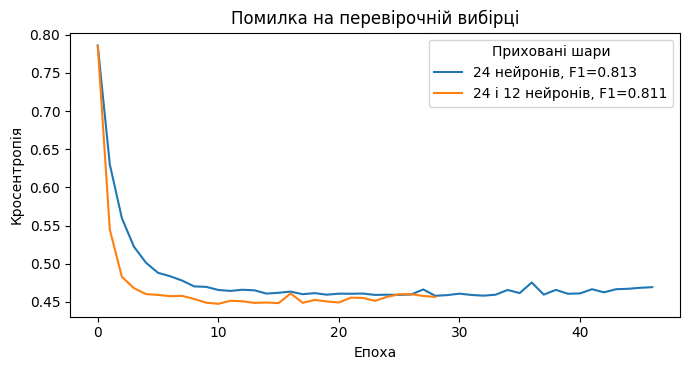

In [5]:
fit_indices, val_indices = train_test_split(np.arange(len(y_train)), test_size=0.20,
                                                   random_state=42, stratify=y_train)
pre_val = make_preprocessor()
X_fit = pre_val.fit_transform(X_train_raw.iloc[fit_indices]).astype(float)
X_val = pre_val.transform(X_train_raw.iloc[val_indices]).astype(float)
y_fit, y_val = y_train[fit_indices], y_train[val_indices]

variants = [(24,), (24, 12)]
validation_models = {}
for shape in variants:
    model = OwnMLP(hidden_layers=shape).fit(X_fit, y_fit, validation=(X_val, y_val))
    score = f1_score(y_val, model.predict(X_val), average="macro")
    validation_models[shape] = (model, score)
    print(f"{len(shape)} прихований шар(и): {' і '.join(map(str, shape))} нейронів; найкраща епоха:", model.best_epoch,
          "validation macro F1:", round(score, 4))

selected_shape = max(variants, key=lambda shape: validation_models[shape][1])
selected_model = validation_models[selected_shape][0]
selected_epochs = selected_model.best_epoch
print("Обрано", len(selected_shape), "прихований шар(и) із",
      ' і '.join(map(str, selected_shape)), "нейронами; епох:", selected_epochs)

fig, ax = plt.subplots(figsize=(7, 3.8))
for shape, (model, score) in validation_models.items():
    ax.plot(model.history["validation"], label=f"{' і '.join(map(str, shape))} нейронів, F1={score:.3f}")
ax.set(xlabel="Епоха", ylabel="Кросентропія", title="Помилка на перевірочній вибірці")
ax.legend(title="Приховані шари")
plt.tight_layout()
plt.show()


На перевірочній частині один прихований шар із 24 нейронами дав macro F1 = 0,8126, а два шари — 0,8110. Тому обираю перший варіант. Найкращий стан першої мережі був після 29-ї епохи; саме стільки епох використовую при остаточному навчанні.


## 6. Остаточне навчання й порівняння

Після вибору архітектури навчаю власний MLP заново на всій навчальній вибірці. Для порівняння навчаю готовий `MLPClassifier` з тією самою кількістю шарів і тими самими підготовленими ознаками. На тесті параметри вже не підбираю.


In [6]:
pre_final = make_preprocessor()
X_train = pre_final.fit_transform(X_train_raw).astype(float)
X_test = pre_final.transform(X_test_raw).astype(float)
print("Ознак після кодування:", X_train.shape[1])

start = time.perf_counter()
own = OwnMLP(hidden_layers=selected_shape).fit(X_train, y_train, epochs=selected_epochs)
own_seconds = time.perf_counter() - start

start = time.perf_counter()
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=UserWarning)
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    library_model = MLPClassifier(hidden_layer_sizes=selected_shape, activation="relu", solver="adam",
                                  alpha=0.0001, batch_size=128, learning_rate_init=0.003,
                                  max_iter=selected_epochs, random_state=42, tol=0,
                                  n_iter_no_change=selected_epochs + 1)
    library_model.fit(X_train, y_train)
library_seconds = time.perf_counter() - start


def get_metrics(name, model, runtime):
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    return {"Модель": name,
            "Train accuracy": accuracy_score(y_train, train_prediction),
            "Test accuracy": accuracy_score(y_test, test_prediction),
            "Train error": 1 - accuracy_score(y_train, train_prediction),
            "Test error": 1 - accuracy_score(y_test, test_prediction),
            "Train macro F1": f1_score(y_train, train_prediction, average="macro"),
            "Test macro F1": f1_score(y_test, test_prediction, average="macro"),
            "Час, с": runtime}


results = pd.DataFrame([get_metrics("Власний MLP", own, own_seconds),
                        get_metrics("sklearn MLP", library_model, library_seconds)])
print(results.round(4).to_string(index=False))
print("\nВласний MLP — деталі на тесті:")
print(classification_report(y_test, own.predict(X_test), target_names=class_names, digits=3))


Ознак після кодування: 49
     Модель  Train accuracy  Test accuracy  Train error  Test error  Train macro F1  Test macro F1  Час, с
Власний MLP          0.8522         0.8268       0.1478      0.1732          0.8525         0.8286  0.5647
sklearn MLP          0.8525         0.8345       0.1475      0.1655          0.8522         0.8354  0.5883

Власний MLP — деталі на тесті:
              precision    recall  f1-score   support

      низька      0.918     0.845     0.880       679
     середня      0.720     0.782     0.750       689
      висока      0.859     0.852     0.856       710

    accuracy                          0.827      2078
   macro avg      0.832     0.827     0.829      2078
weighted avg      0.832     0.827     0.829      2078



Власна мережа правильно визначила 82,68% тестових авто; готова модель — 83,45%. Різниця невелика. На навчальних даних власна модель має 85,22%, тобто тестова точність нижча приблизно на 2,55.

Матриця помилок нижче показує, між якими саме ціновими категоріями модель плутається. Рядки — правильний клас, стовпці — прогноз моделі.


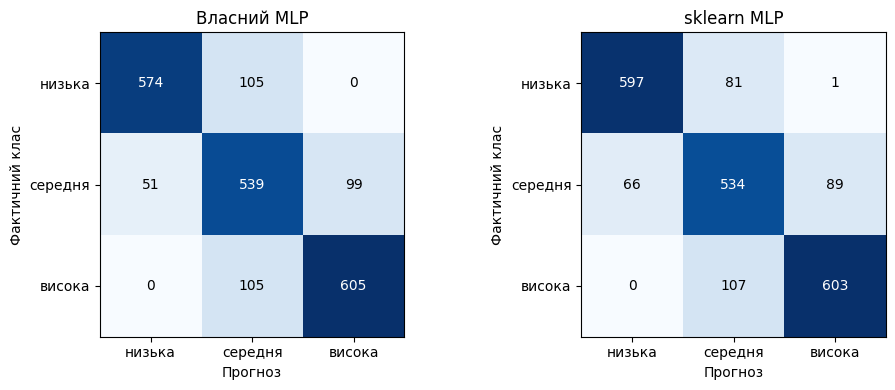

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [("Власний MLP", own), ("sklearn MLP", library_model)]):
    counts = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1, 2])
    ax.imshow(counts, cmap="Blues", vmin=0)
    for row in range(3):
        for column in range(3):
            ax.text(column, row, counts[row, column], ha="center", va="center",
                    color="white" if counts[row, column] > counts.max() / 2 else "black")
    ax.set_xticks(range(3), class_names)
    ax.set_yticks(range(3), class_names)
    ax.set(title=name, xlabel="Прогноз", ylabel="Фактичний клас")
plt.tight_layout()
plt.show()


## 7. Висновок

Власна мережа справді виконує багатокласову класифікацію. Її якість порівнюється з `MLPClassifier` на однакових даних; близькість результатів підтверджує роботу прямого й зворотного проходу. Точні показники наведено вище, разом із помилками на навчанні та тесті. Найчастіше складно відрізнити автомобілі сусідніх цінових категорій поблизу їхньої межі.

**Контрольні питання.** MLP — мережа з вхідним, одним чи кількома прихованими та вихідним шарами. Прихований шар перетворює ознаки й допомагає вловити нелінійні залежності, які не описує один лінійний персептрон.
